## <회전(rotation) 변환>

### 기본 라이브러리 불러오기

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import math

### User parameter 정의하기

In [12]:
theta = -45 # degree : 사람이 생각하는 각도
theta_rad = theta * np.pi / 180 # 컴퓨터가 사용하는 각도 체계 radian

R = np.array([[math.cos(theta_rad),-math.sin(theta_rad)],
               [math.sin(theta_rad),math.cos(theta_rad)]])

R = np.array([[math.cos(theta_rad),-math.sin(theta_rad),0],
               [math.sin(theta_rad),math.cos(theta_rad),0],
               [0,0,1]])

### ‘cat.jpg’를 흑백영상(f)으로 읽고, 영상의 크기(h,w)를 자동으로 구하기

In [13]:
f = cv2.imread("images/cat.jpg",0) # gray
h,w = f.shape

print(h,w)

400 600


### 결과 영상(g) 생성하기

In [14]:
g = np.zeros((h,w))
gh, gw = g.shape

### 회전 구현하기

In [15]:
for x in range(0,h):
    for y in range(0,w):
        x_prime = int(x * math.cos(theta_rad) - y * math.sin(theta_rad))
        y_prime = int(x * math.sin(theta_rad) + y * math.cos(theta_rad))
        if (0 <= x_prime < gh) and (0 <= y_prime < gw):
            g[x_prime,y_prime] = f[x,y]

# 8bit unsigned integer format
g = g.astype("uint8")            

### matplot 라이브러리를 활용하여 영상(f,g) 출력하기

(np.float64(-0.5), np.float64(599.5), np.float64(399.5), np.float64(-0.5))

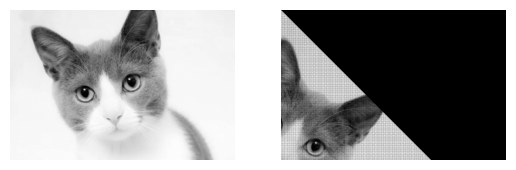

In [16]:
plt.subplot(1,2,1); plt.imshow(f, cmap="gray"); plt.axis("off")
plt.subplot(1,2,2); plt.imshow(g, cmap="gray"); plt.axis("off")